# Model testing
This file is for testing and creating the best ml model for trading predictions and building it in python then implement in cpp

## Main Idea
To find the best model fit... the objective of the model is to predict if the currency pair will increase over the next 15min ? and make a reccomandation to either trade or not 

In [30]:
import math 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os 
import seaborn as sns

In [31]:
data_eur_usd = pd.read_csv("../data/ohlc_eur_usd.csv")
data_aud_usd = pd.read_csv("../data/ohlc_aud_usd.csv")

In [32]:
print(data_eur_usd.head(), '\n\n')
print(data_eur_usd.info(), '\n\n')

                        date     pair      open      high       low     close
0  2024-11-20 17:15:00-05:00  EUR_USD  1.054275  1.054290  1.054240  1.054260
1  2024-11-20 17:16:00-05:00  EUR_USD  1.054260  1.054285  1.054260  1.054270
2  2024-11-20 17:17:00-05:00  EUR_USD  1.054270  1.054275  1.054225  1.054250
3  2024-11-20 17:18:00-05:00  EUR_USD  1.054250  1.054270  1.054240  1.054265
4  2024-11-20 17:19:00-05:00  EUR_USD  1.054265  1.054265  1.054245  1.054250 


<class 'pandas.DataFrame'>
RangeIndex: 74810 entries, 0 to 74809
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    74810 non-null  str    
 1   pair    74810 non-null  str    
 2   open    74810 non-null  float64
 3   high    74810 non-null  float64
 4   low     74810 non-null  float64
 5   close   74810 non-null  float64
dtypes: float64(4), str(2)
memory usage: 3.4 MB
None 




In [33]:
data_eur_usd.describe()

,open,high,low,close
count,74810.000000,74810.000000,74810.000000,74810.000000
mean,1.041574,1.041656,1.041492,1.041574
std,0.009100,0.009099,0.009102,0.009100
min,1.017980,1.018810,1.017755,1.017980
25%,1.035300,1.035376,1.035230,1.035300
50%,1.041290,1.041375,1.041200,1.041290
75%,1.049315,1.049380,1.049240,1.049315
max,1.062195,1.062990,1.062120,1.062195


In [34]:
print(data_aud_usd.head(), '\n\n')
print(data_aud_usd.info(), '\n\n')

                        date     pair      open      high       low     close
0  2024-11-20 22:15:00+00:00  AUD_USD  0.650425  0.650435  0.650380  0.650410
1  2024-11-20 22:16:00+00:00  AUD_USD  0.650410  0.650415  0.650380  0.650395
2  2024-11-20 22:17:00+00:00  AUD_USD  0.650395  0.650430  0.650395  0.650415
3  2024-11-20 22:18:00+00:00  AUD_USD  0.650415  0.650445  0.650415  0.650440
4  2024-11-20 22:19:00+00:00  AUD_USD  0.650440  0.650440  0.650440  0.650440 


<class 'pandas.DataFrame'>
RangeIndex: 725122 entries, 0 to 725121
Data columns (total 6 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    725122 non-null  str    
 1   pair    725122 non-null  str    
 2   open    725122 non-null  float64
 3   high    725122 non-null  float64
 4   low     725122 non-null  float64
 5   close   725122 non-null  float64
dtypes: float64(4), str(2)
memory usage: 33.2 MB
None 




In [35]:
data_aud_usd.describe()

,open,high,low,close
count,725122.000000,725122.000000,725122.000000,725122.000000
mean,0.708335,0.708396,0.708273,0.708335
std,0.117011,0.117017,0.117005,0.117011
min,0.592235,0.592345,0.591420,0.592235
25%,0.648115,0.648185,0.648055,0.648115
50%,0.669320,0.669370,0.669270,0.669320
75%,0.707190,0.707255,0.707129,0.707190
max,1.062195,1.062990,1.062120,1.062195


# Graphing data 

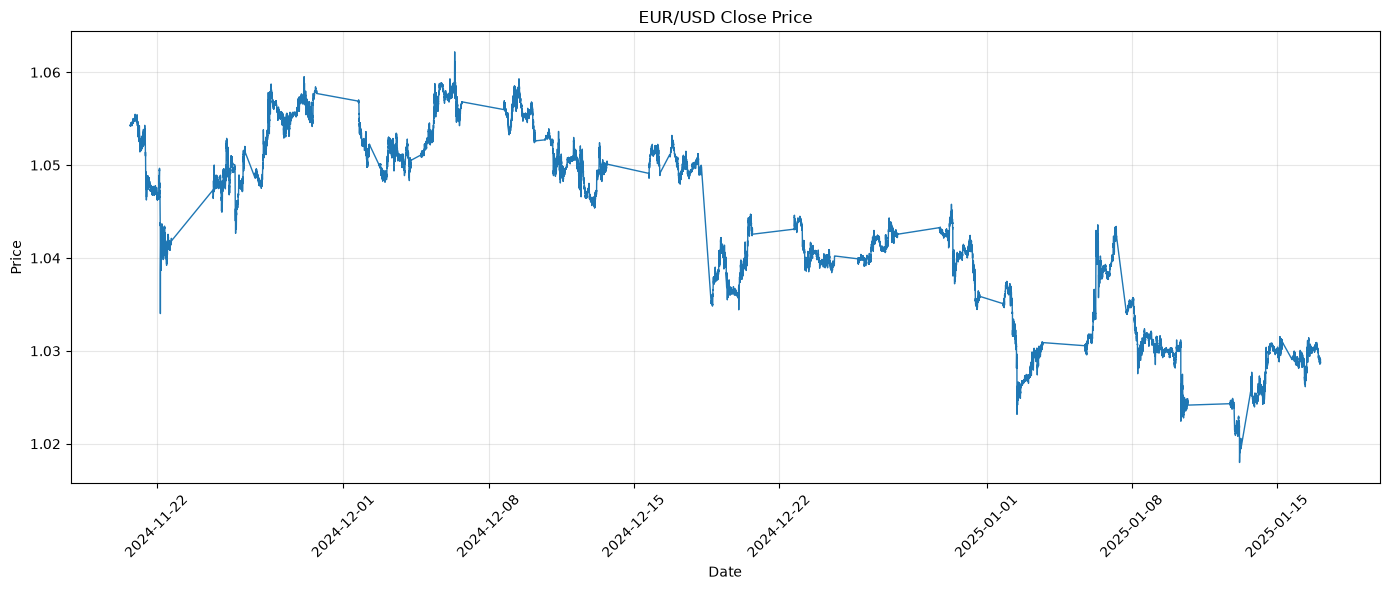

In [36]:
data_eur_usd['date'] = pd.to_datetime(data_eur_usd['date'])
data_sample = data_eur_usd.head(50000)
plt.figure(figsize=(14, 6))
plt.plot(data_sample['date'], data_sample['close'], linewidth=1)
plt.title('EUR/USD Close Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

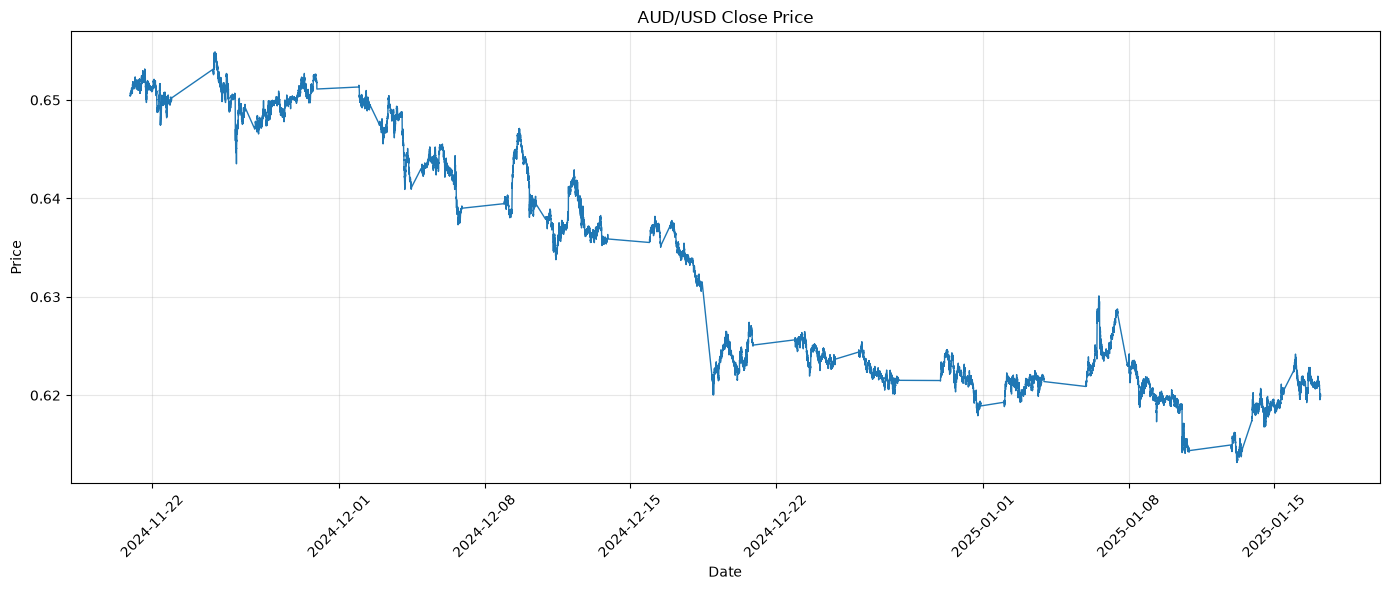

In [37]:
data_aud_usd['date'] = pd.to_datetime(data_aud_usd['date'])
data_sample = data_aud_usd.head(50000)
plt.figure(figsize=(14, 6))
plt.plot(data_sample['date'], data_sample['close'], linewidth=1)
plt.title('AUD/USD Close Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
sns.set_theme(style="whitegrid")

df_eur_usd = data_eur_usd.copy()

# Convert dates
df_eur_usd['date'] = pd.to_datetime(df_eur_usd['date'], errors='coerce')

# Convert OHLC columns to numeric
price_cols = ['open', 'high', 'low', 'close']

for col in price_cols:
    df_eur_usd[col] = pd.to_numeric(df_eur_usd[col], errors='coerce')

print("Dataset shape:", df_eur_usd.shape)
print("\nData types:")
print(df_eur_usd.dtypes)

print("\nMissing values:")
print(df_eur_usd.isnull().sum())

print("\nSummary statistics:")
print(df_eur_usd.describe())

Dataset shape: (74810, 6)

Data types:
date     datetime64[us, UTC-05:00]
pair                           str
open                       float64
high                       float64
low                        float64
close                      float64
dtype: object

Missing values:
date     0
pair     0
open     0
high     0
low      0
close    0
dtype: int64

Summary statistics:
               open          high           low         close
count  74810.000000  74810.000000  74810.000000  74810.000000
mean       1.041574      1.041656      1.041492      1.041574
std        0.009100      0.009099      0.009102      0.009100
min        1.017980      1.018810      1.017755      1.017980
25%        1.035300      1.035376      1.035230      1.035300
50%        1.041290      1.041375      1.041200      1.041290
75%        1.049315      1.049380      1.049240      1.049315
max        1.062195      1.062990      1.062120      1.062195


In [42]:
sns.set_theme(style="whitegrid")

df_aud_usd = data_aud_usd.copy()

# Convert dates
df_aud_usd['date'] = pd.to_datetime(df_aud_usd['date'], errors='coerce')

# Convert OHLC columns to numeric
price_cols = ['open', 'high', 'low', 'close']

for col in price_cols:
    df_aud_usd[col] = pd.to_numeric(df_aud_usd[col], errors='coerce')

print("Dataset shape:", df_aud_usd.shape)
print("\nData types:")
print(df_aud_usd.dtypes)

print("\nMissing values:")
print(df_aud_usd.isnull().sum())

print("\nSummary statistics:")
print(df_aud_usd.describe())

Dataset shape: (725122, 6)

Data types:
date     datetime64[us, UTC]
pair                     str
open                 float64
high                 float64
low                  float64
close                float64
dtype: object

Missing values:
date     0
pair     0
open     0
high     0
low      0
close    0
dtype: int64

Summary statistics:
                open           high            low          close
count  725122.000000  725122.000000  725122.000000  725122.000000
mean        0.708335       0.708396       0.708273       0.708335
std         0.117011       0.117017       0.117005       0.117011
min         0.592235       0.592345       0.591420       0.592235
25%         0.648115       0.648185       0.648055       0.648115
50%         0.669320       0.669370       0.669270       0.669320
75%         0.707190       0.707255       0.707129       0.707190
max         1.062195       1.062990       1.062120       1.062195


In [44]:
# Keep original data untouched
df_eur_usd = df_eur_usd.dropna(subset=['date', 'pair'] + price_cols)

# Remove duplicate candles
df_eur_usd = df_eur_usd.drop_duplicates(subset=['date', 'pair'])

# Remove invalid prices
df_eur_usd = df_eur_usd[(df_eur_usd[price_cols] > 0).all(axis=1)]

# Validate OHLC relationships
valid_ohlc = (
    (df_eur_usd['high'] >= df_eur_usd[['open', 'close', 'low']].max(axis=1)) &
    (df_eur_usd['low'] <= df_eur_usd[['open', 'close', 'high']].min(axis=1))
)

invalid_count = (~valid_ohlc).sum()
print("Invalid OHLC candles:", invalid_count)

df_eur_usd = df_eur_usd[valid_ohlc].copy()

# Sort chronologically
df_eur_usd = df_eur_usd.sort_values(['pair', 'date']).reset_index(drop=True)

print("\nCleaned dataset:", df_eur_usd.shape)

Invalid OHLC candles: 0

Cleaned dataset: (74810, 6)


In [45]:
# Keep original data untouched
df_aud_usd = df_aud_usd.dropna(subset=['date', 'pair'] + price_cols)

# Remove duplicate candles
df_aud_usd = df_aud_usd.drop_duplicates(subset=['date', 'pair'])

# Remove invalid prices
df_aud_usd = df_aud_usd[(df_aud_usd[price_cols] > 0).all(axis=1)]

# Validate OHLC relationships
valid_ohlc = (
    (df_aud_usd['high'] >= df_aud_usd[['open', 'close', 'low']].max(axis=1)) &
    (df_aud_usd['low'] <= df_aud_usd[['open', 'close', 'high']].min(axis=1))
)

invalid_count = (~valid_ohlc).sum()
print("Invalid OHLC candles:", invalid_count)

df_aud_usd = df_aud_usd[valid_ohlc].copy()

# Sort chronologically
df_aud_usd = df_aud_usd.sort_values(['pair', 'date']).reset_index(drop=True)

print("\nCleaned dataset:", df_aud_usd.shape)

Invalid OHLC candles: 0

Cleaned dataset: (725122, 6)


# Data distrubutions

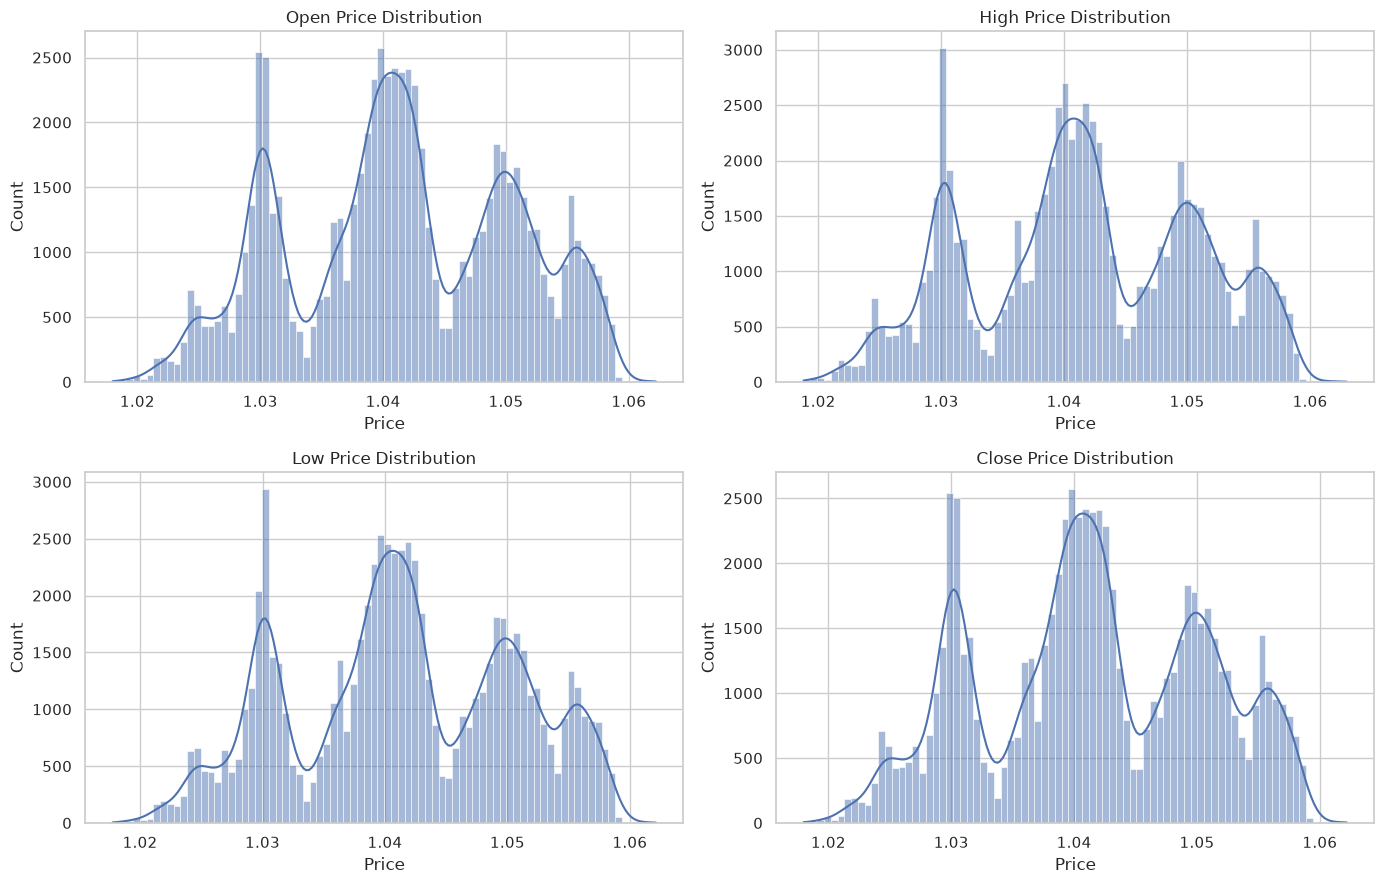

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(price_cols, axes.flatten()):
    sns.histplot(df_eur_usd[col], bins=80, kde=True, ax=ax)
    ax.set_title(f'{col.capitalize()} Price Distribution')
    ax.set_xlabel('Price')

plt.tight_layout()
plt.show()

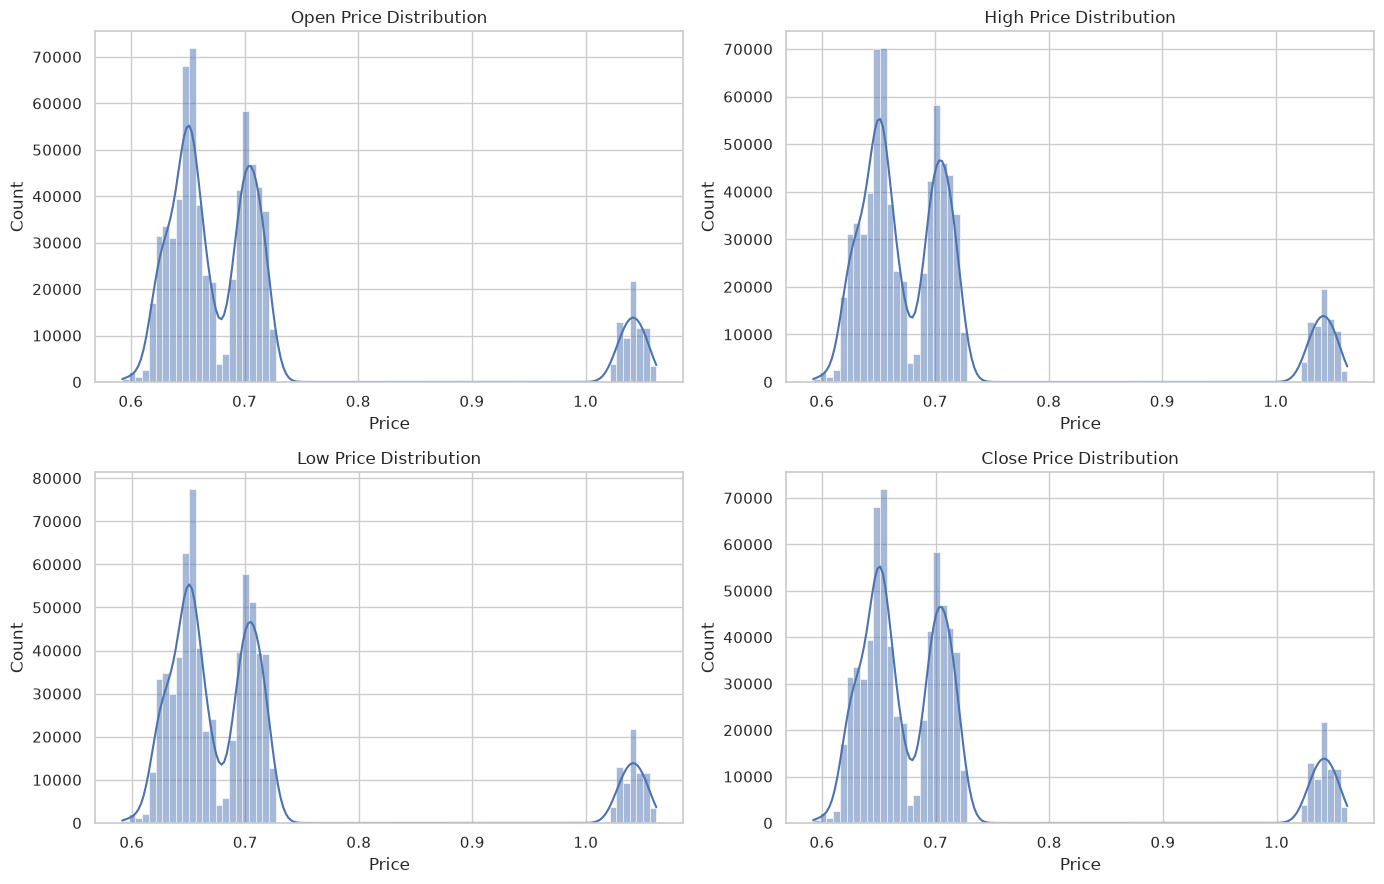

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(price_cols, axes.flatten()):
    sns.histplot(df_aud_usd[col], bins=80, kde=True, ax=ax)
    ax.set_title(f'{col.capitalize()} Price Distribution')
    ax.set_xlabel('Price')

plt.tight_layout()
plt.show()

In [48]:
df_eur_usd['returns'] = df_eur_usd.groupby('pair')['close'].pct_change()

df_eur_usd['log_returns'] = np.log(
    df_eur_usd['close'] / df_eur_usd.groupby('pair')['close'].shift(1)
)

df_eur_usd['candle_body'] = df_eur_usd['close'] - df_eur_usd['open']

df_eur_usd['candle_range'] = df_eur_usd['high'] - df_eur_usd['low']

df_eur_usd['upper_wick'] = (
    df_eur_usd['high'] - df_eur_usd[['open', 'close']].max(axis=1)
)

df_eur_usd['lower_wick'] = (
    df_eur_usd[['open', 'close']].min(axis=1) - df_eur_usd['low']
)

features_eur_usd = [
    'returns',
    'log_returns',
    'candle_body',
    'candle_range',
    'upper_wick',
    'lower_wick'
]

In [49]:
df_aud_usd['returns'] = df_aud_usd.groupby('pair')['close'].pct_change()

df_aud_usd['log_returns'] = np.log(
    df_aud_usd['close'] / df_aud_usd.groupby('pair')['close'].shift(1)
)

df_aud_usd['candle_body'] = df_aud_usd['close'] - df_aud_usd['open']

df_aud_usd['candle_range'] = df_aud_usd['high'] - df_aud_usd['low']

df_aud_usd['upper_wick'] = (
    df_aud_usd['high'] - df_aud_usd[['open', 'close']].max(axis=1)
)

df_aud_usd['lower_wick'] = (
    df_aud_usd[['open', 'close']].min(axis=1) - df_aud_usd['low']
)

features_aud_usd = [
    'returns',
    'log_returns',
    'candle_body',
    'candle_range',
    'upper_wick',
    'lower_wick'
]

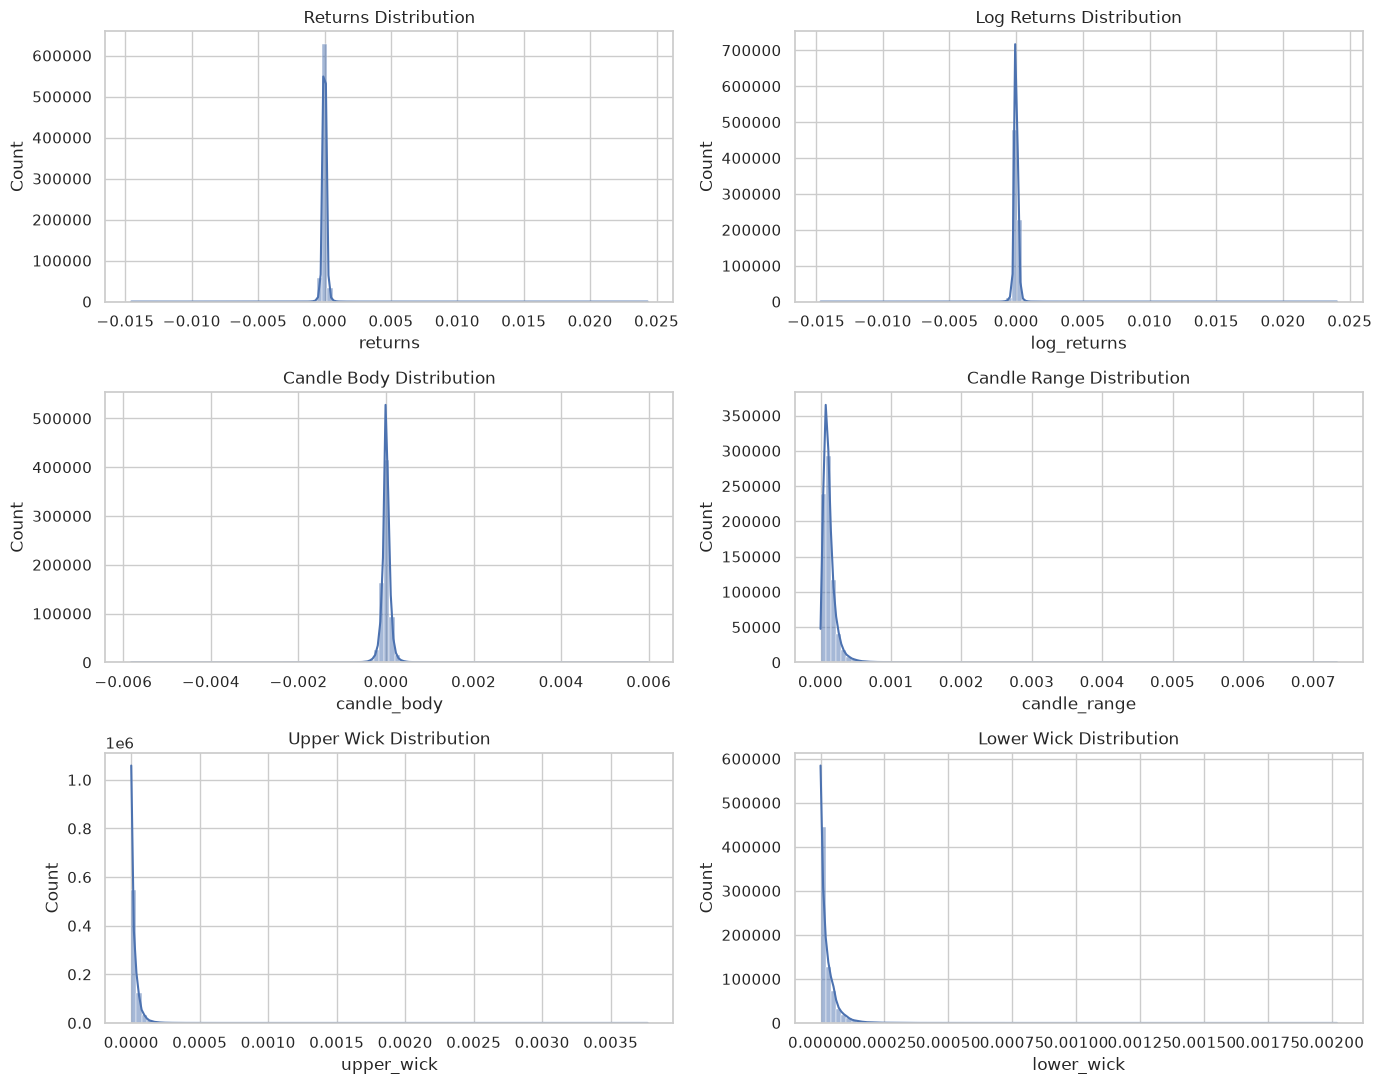

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for col, ax in zip(features_aud_usd, axes.flatten()):
    sns.histplot(
        df_aud_usd[col].dropna(),
        bins=100,
        kde=true,
        ax=ax
    )
    ax.set_title(f'{col.replace("_", " ").title()} distribution')

plt.tight_layout()
plt.show()

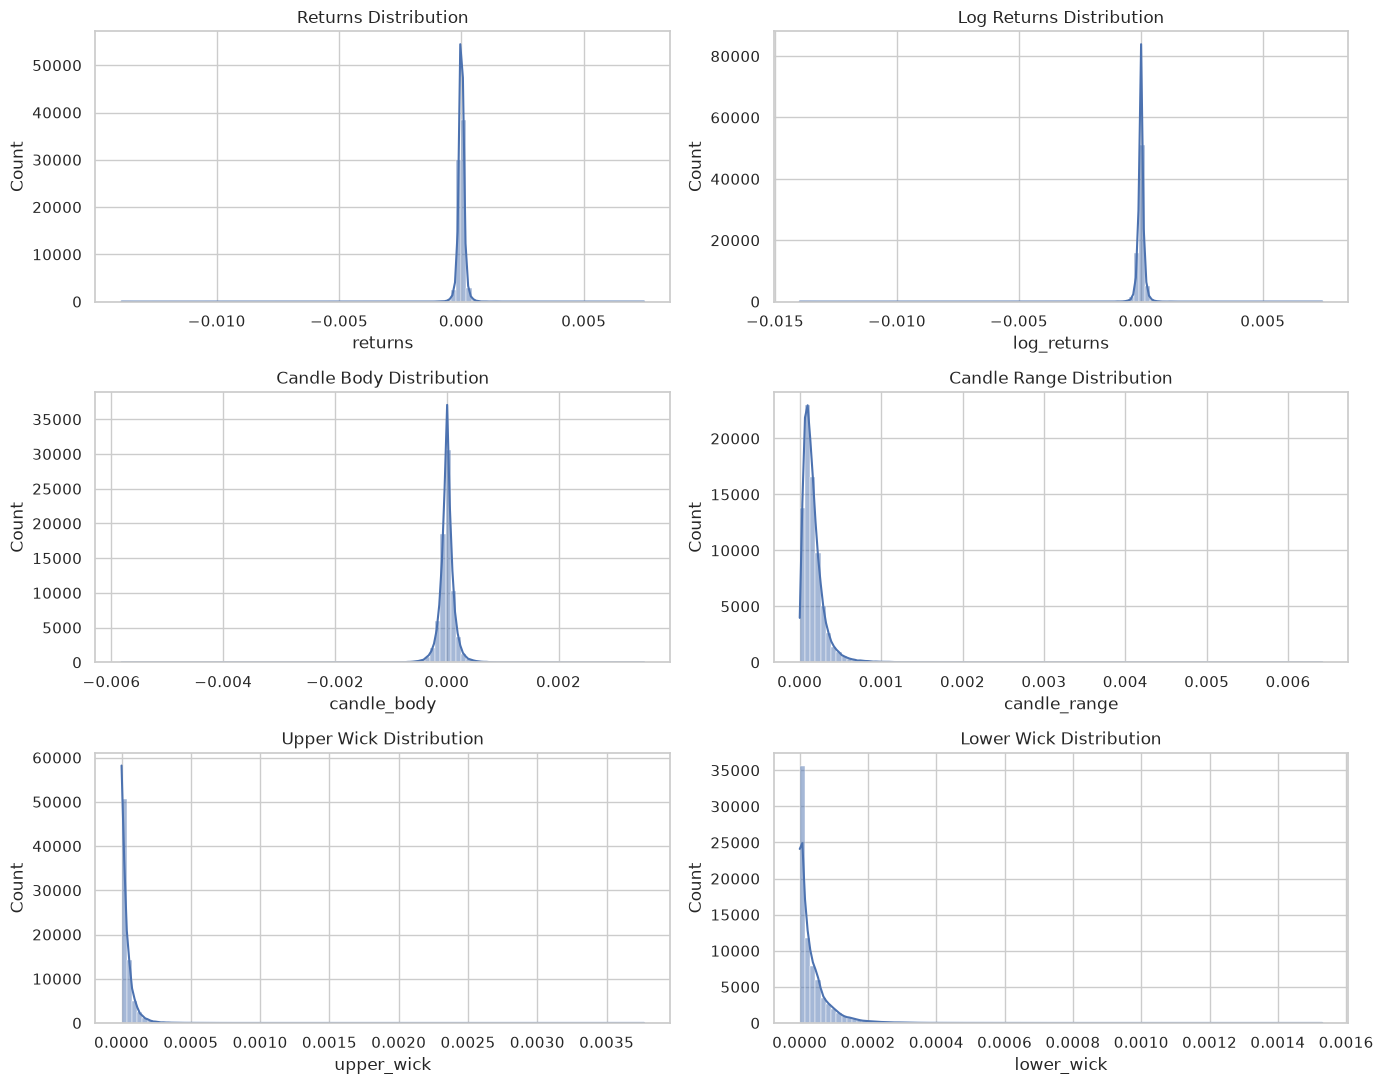

In [51]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for col, ax in zip(features_eur_usd, axes.flatten()):
    sns.histplot(
        df_eur_usd[col].dropna(),
        bins=100,
        kde=True,
        ax=ax
    )
    ax.set_title(f'{col.replace("_", " ").title()} Distribution')

plt.tight_layout()
plt.show()


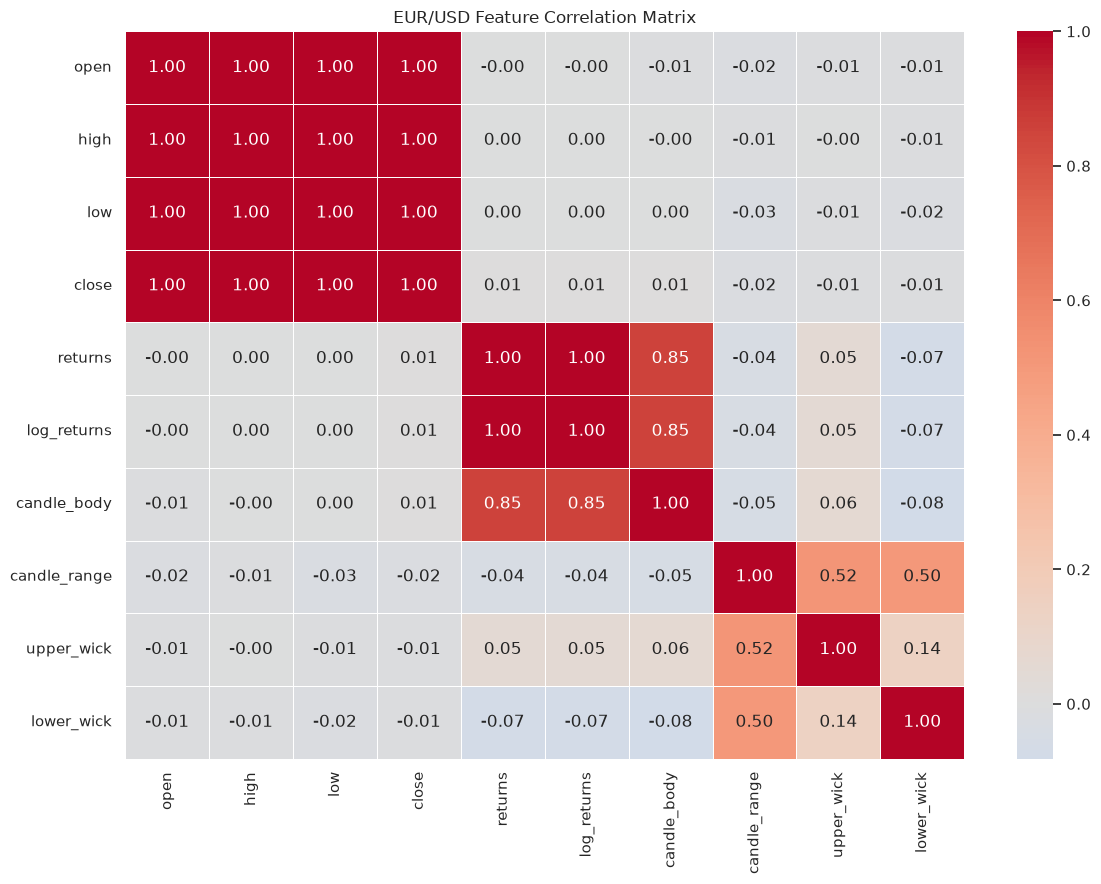

In [52]:
correlation_cols = price_cols + features_eur_usd

corr = df_eur_usd[correlation_cols].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('EUR/USD Feature Correlation Matrix')
plt.tight_layout()
plt.show()


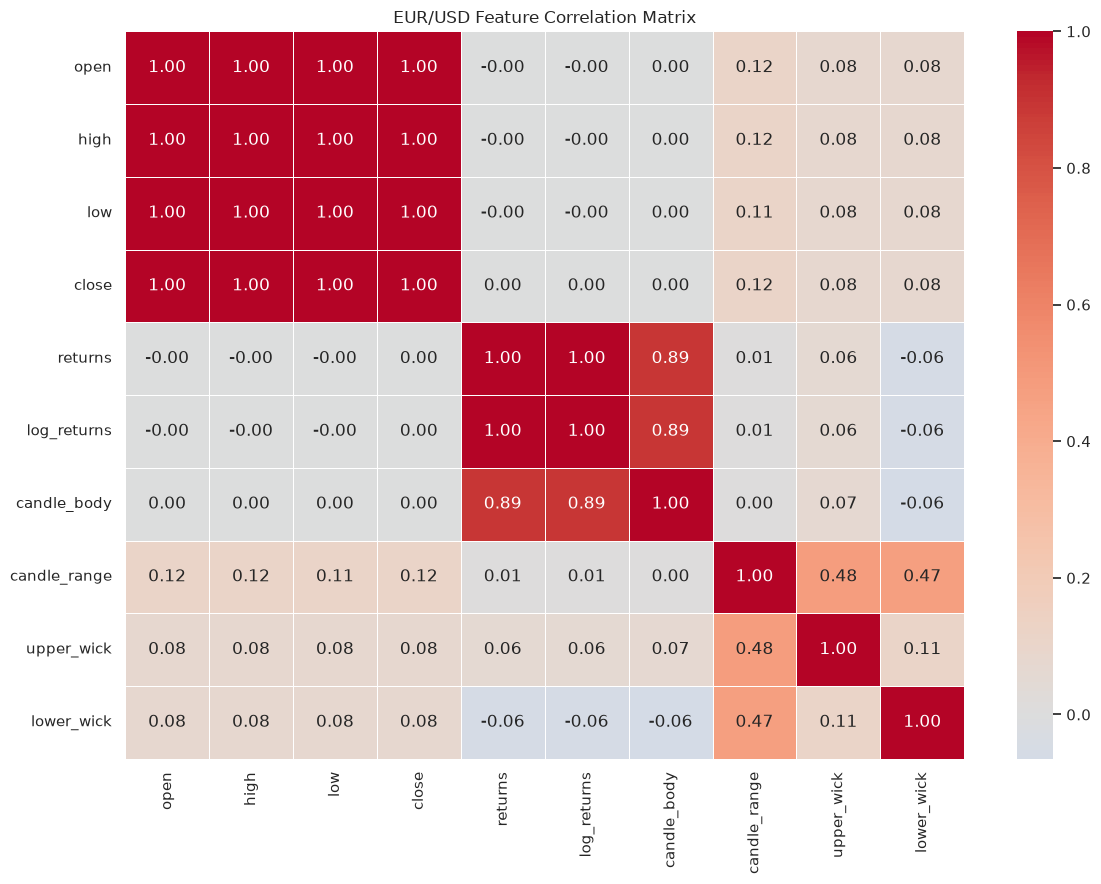

In [53]:
correlation_cols = price_cols + features_aud_usd

corr = df_aud_usd[correlation_cols].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('EUR/USD Feature Correlation Matrix')
plt.tight_layout()
plt.show()
